# 5 Brownian dynamics

## Optical tweezers

<div style="background-color:#f0f8ff; border:2px solid #4682b4; padding:12px; border-radius:4px;">
<strong>Note:</strong> This notebook contains the code for section 5.4 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

A focused laser can trap and confine a microscopic particle. 

We see how we simulate this phenomenon.

<a id="optical-trap"></a>
## 5.4 Optical tweezers

Langevin equation for a Brownian particle in a optical trap (Eq. (5.8)):

$$m\ddot x= -k x -\gamma\dot x+\sqrt{2k_\mathrm{B}T\gamma}\,W(t),$$

Optical trap: harmonic trap.<br>
Trapping potential: $U(x)=\frac{k}{2}x^2$<br>
Confining (restoring) force $F=-kx$

In the overdamped regime (Eq. (5.9)):

$$x_{i+1}=x_i-\frac{k}{\gamma}x_i\Delta t+\sqrt{\frac{2k_\mathrm{B}T\Delta t}{\gamma}}\,w_i.$$

Position relaxation time $\quad \tau_x=\gamma/k \quad$ 
imposes: $\Delta t\ll\tau_x$. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng() 

We simulate a 2D trap

In [2]:
k_B = 1.380649e-23  # J/K
T = 300.0            # K
R = 1e-6             # m
eta = 0.001          # Pa s
gamma = 6 * np.pi * eta * R
D = k_B * T / gamma  # m^2 / s
kx = 1e-6            # N/m = 1 pN/um
ky = 0.25e-6         # N/m = 0.25 pN/um
tau_x = gamma / kx
tau_y = gamma / ky
print(f"tau_x = {tau_x:.3f} s")
print(f"tau_y = {tau_y:.3f} s")

tau_x = 0.019 s
tau_y = 0.075 s


We prepare to generate the trajectory

In [3]:
dt = tau_x / 60  # note 
n_steps = 70000

position = np.zeros((n_steps + 1, 2))

stiffness = np.array([kx, ky])

noise = rng.standard_normal((n_steps, 2))

We generate the trajectory

In [4]:
thermal_step = np.sqrt(2 * D * dt)

for i in range(n_steps):
    restoring_step = (
        -stiffness * position[i] * dt / gamma
    )
    position[i + 1] = (
        position[i] 
        + restoring_step 
        + thermal_step * noise[i]
    )

We allow the initial position to relax before measuring equilibrium statistics. 

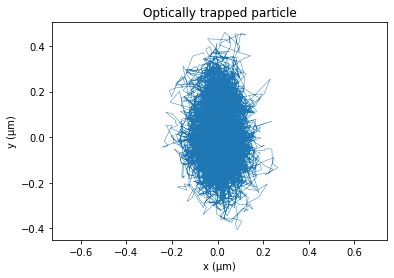

In [5]:
relaxed_in = round(10 * tau_y / dt)  # note 

equilibrium = position[relaxed_in:]

xy_um = equilibrium * 1e6

plt.plot(
    xy_um[::10, 0],  # x 
    xy_um[::10, 1],  # y 
    lw=0.45
)
plt.xlabel("x (µm)")
plt.ylabel("y (µm)")
plt.axis("equal")
plt.title("Optically trapped particle");

<a id="distribution"></a>
At **equilibrium**

Probability distribution: $p(x)\propto\exp\left(-\frac{U(x)}{k_\mathrm{B}T}\right) \qquad$ (Eq. (5.10))

Positional variance: $\sigma_x^2=\frac{k_\mathrm{B}T}{k_x}\qquad$ (Eq. (5.12))


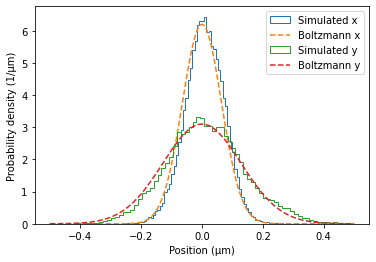

In [6]:
sigma_x = np.sqrt(k_B * T / kx) * 1e6  # µm
sigma_y = np.sqrt(k_B * T / ky) * 1e6

xx = np.linspace(-0.5, 0.5, 350)

fig, ax = plt.subplots()

for data, sigma, name in [(xy_um[:, 0], sigma_x, "x"),
                          (xy_um[:, 1], sigma_y, "y")]:
    ax.hist(
        data, 
        bins=70, 
        density=True, 
        histtype="step", 
        label=f"Simulated {name}"
    )
    ax.plot(
        xx, 
        np.exp(-xx**2 / (2 * sigma**2)) 
        / (np.sqrt(2 * np.pi) * sigma), 
        "--", 
        label=f"Boltzmann {name}"
    )
    
ax.set(xlabel="Position (µm)", ylabel="Probability density (1/µm)")
ax.legend();

<a id="autocorrelation"></a>

Position autocorrelation function: $C_x(t)= \frac{k_\mathrm{B}T}{k_x}\exp\left(-\frac{k_x t}{\gamma}\right) \qquad$ (Eq. 5.11)

$t$ indicates the lag time

In [7]:
n_lags = round(5 * tau_y / dt)

lag_seconds = np.arange(n_lags + 1) * dt

covariance = np.empty((n_lags + 1, 2))

centered = equilibrium - equilibrium.mean(axis=0)

We calculate the autocorrelation function for x and y

In [8]:
for lag in range(n_lags + 1):
    if lag == 0:
        covariance[lag] = np.mean(centered**2, axis=0)
    else:
        covariance[lag] = (
            np.mean(centered[lag:] * centered[:-lag], axis=0)
        )

We plot the autocorrelation functions for x and y

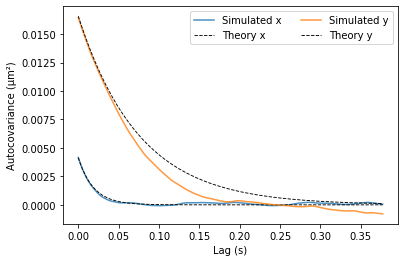

In [9]:
fig, ax = plt.subplots()    

for j, (k, name) in enumerate(zip(stiffness, ["x", "y"])):
    ax.plot(
        lag_seconds, 
        covariance[:, j] * 1e12,
        label=f"Simulated {name}", 
        alpha=0.8
    )
    ax.plot(
        lag_seconds, 
        (k_B * T / k) * np.exp(-k * lag_seconds / gamma) * 1e12, 
        "k--", 
        lw=0.9, 
        label=f"Theory {name}"
    )
    
ax.set(xlabel="Lag (s)", ylabel="Autocovariance (µm²)")
ax.legend(ncol=2);

<a id="calibration"></a>
We can infer $k$ from variance or correlation:  

$k_{\mathrm{var}}=k_\mathrm{B}T/\sigma_x^2$ 

$k_{\mathrm{corr}}=\gamma/\tau_x$, 

In [10]:
measured_variances = equilibrium.var(axis=0)

k_var = k_B * T / measured_variances

for j, axis in enumerate(["x", "y"]):
    normalized_c = covariance[:, j] / covariance[0, j]
    below = normalized_c < np.exp(-1)
    # check whether a crossing exist
    if np.any(below):      
        first_below = np.flatnonzero(below)[0]
        tau_measured = lag_seconds[first_below]
        k_corr = gamma / tau_measured
    else:  
        # if id doesn't exist, we can't extimate k_corr
        k_corr = np.nan
        print(f"Warning: no threshold crossing for {axis}")
    
    print("")
    print(f"k{axis}:   {stiffness[j] * 1e6:.3f} pN/µm")
    print(
        f"k{axis}_var:  {k_var[j] * 1e6:.3f} pN/µm"
    )
    print(
        f"k{axis}_corr: {k_corr * 1e6:.3f} pN/µm"
    )


kx:   1.000 pN/µm
kx_var:  0.997 pN/µm
kx_corr: 1.053 pN/µm

ky:   0.250 pN/µm
ky_var:  0.252 pN/µm
ky_corr: 0.284 pN/µm


<a id="stiffness-sigma"></a>

Now we change trap stiffness while holding temperature, viscosity, and the numerical time step fixed. 

We use the chapter module.


In [11]:
# The same calculations, now available as a reusable module.
from pathlib import Path
import sys
sys.path.insert(0, "../05_modules")
import brownian_dynamics as bd

We generate the trajectories for different `k` (stiffness)

In [12]:
stiffness_values = np.linspace(0.25, 1.5, 10) * 1e-6  # N/m
variance_values = []
sweep_dt = gamma / max(stiffness_values) / 60
for stiffness_k in stiffness_values:
    thermal_noise = rng.standard_normal(24000)
    trajectory = bd.trapped_overdamped(
        thermal_noise, 
        sweep_dt, 
        gamma, 
        T, 
        stiffness_k
    )
    variance_values.append(np.var(trajectory[3000:]))
variance_values = np.array(variance_values)

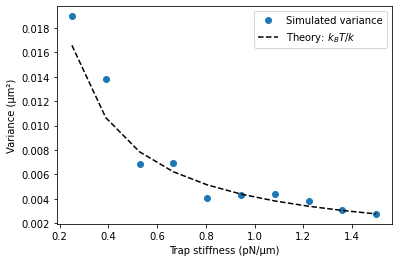

In [13]:
fig, ax = plt.subplots()
ax.plot(
    stiffness_values * 1e6, 
    variance_values * 1e12, 
    "o",
    label="Simulated variance"
)
ax.plot(
    stiffness_values * 1e6, 
    k_B * T / stiffness_values * 1e12,
    "k--", 
    label=r"Theory: $k_B T/k$"
)
ax.set(
    xlabel="Trap stiffness (pN/µm)", 
    ylabel="Variance (µm²)"
)
ax.legend();

Let's see an interatcive animation:

In [14]:
import bd_visualize as vi
# Widget animation advances the simulation as frames are requested.
# No pygame.display.set_mode() or external desktop window is used.
animation = vi.animate_optical_trap(
    gamma, T, stiffness_x=kx, stiffness_y=ky,
    dt=2e-4, steps_per_frame=12, frames=220,
)

pygame 2.5.2 (SDL 2.28.3, Python 3.8.5)
Hello from the pygame community. https://www.pygame.org/contribute.html


<a id="questions"></a>

## Questions

Here are the questions:

- [Q9: Optical trap](#q9)
- [Q10: Distributions](#q10)
- [Q11: Calibration](#q11)
- [Q12: Stiffness vs variance](#q12)

<a id="q9"></a>
**Question 9: Optical trap.**  

Refer to [optical tweezers](#optical-trap).  

[Go back to questions](#questions)

a. In the notebook, the optical trap has different stiffnesses, `kx` and `ky`. Why does the particle explore a larger region along one direction than the other?

b. Suppose we make `kx = ky`. How would the 2D trajectory change? What would you expect the shape of the region explored by the particle to look like?

c. The notebook uses `dt = tau_x / 60`. What might happen if we increase `dt` to a value comparable to `tau_x`? Why is the choice of time step more important here than for free diffusion?

<a id="q10"></a>
**Question 10: Distribution.**  

Refer to [distribution](#distribution) and [autocorrelation](#autocorrelation)

[Go back to questions](#questions)

a. The position distributions along x and y have different widths. How are these widths related to the trap stiffnesses?

b. The autocorrelation functions along x and y decay at different rates. Which direction decays faster, and why?

<a id="q11"></a>
**Question 11: Calibration.**  

Refer to [calibration](#calibration).  

[Go back to questions](#questions)

a. The notebook estimates trap stiffness using both positional variance (`k_var`) and autocorrelation (`k_corr`). Why do they not agree perfectly?

b. Suppose we shorten the simulated trajectory considerably. Would you expect `k_var` and `k_corr` to agree as closely with the input stiffness? Explain why.

c. Imagine you are given experimental trajectories from an optical trap, but the laser's trapping stiffness is unknown. How could you estimate the stiffness using the methods implemented in the notebook?

<a id="q12"></a>
**Question 12: Stiffness vs variance.**  

Refer to [stiffness vs variance](#stiffness-sigma).  

[Go back to questions](#questions)

a. Suppose we extend stiffness_values to include much larger stiffnesses without changing `sweep_dt`. Would you still expect the simulated variance to agree with the theoretical prediction? Explain why.

b. Suppose the temperature is increased while the stiffness is kept fixed. How would the variance-versus-stiffness curve change? Explain the physical reason.